### Inlämningsuppgift - analys av Hälsostudie
_Kurs: Pythonprogrammering och statistisk dataanalys_

_Student: Ulrika Truedsson_

___

### Förberedelse

- Läs in och granska datasetet
- Undersök vad som anses vara normalvärde för hälsomarkörerna som finns med i studien

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_raw = pd.read_csv("data/health_study_dataset.csv")

In [2]:
display(data_raw.head())
display(data_raw.info())
display(data_raw.describe())
display(data_raw.describe(include = ['str']))

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


None

,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,171.849250,73.413000,149.178625,4.929150,0.058750
std,231.0844,14.501118,9.804259,13.685059,12.793360,0.848413,0.235303
min,1.0000,18.000000,144.400000,33.700000,106.800000,2.500000,0.000000
25%,200.7500,39.000000,164.775000,64.800000,140.900000,4.327500,0.000000
50%,400.5000,50.000000,171.350000,73.200000,149.400000,4.970000,0.000000
75%,600.2500,59.000000,178.925000,82.600000,157.600000,5.482500,0.000000
max,800.0000,90.000000,200.400000,114.400000,185.900000,7.880000,1.000000


,sex,smoker
count,800,800
unique,2,2
top,F,No
freq,403,587


In [3]:
data = data_raw.copy()

# change datatype on column "smoker" to int
data.loc[data["smoker"] == "No", "smoker"] = "0"
data.loc[data["smoker"] == "Yes", "smoker"] = "1"
data["smoker"] = data["smoker"].astype(int)

# add a column for bmi
data["bmi"] = (data["weight"] / (data["height"] / 100) ** 2).round(2)
data = data[["id", "age", "sex", "weight", "height", "bmi", "systolic_bp", "cholesterol", "smoker", "disease"]]

display(data.info(), data.describe(), data.describe(include = ['str']))

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   weight       800 non-null    float64
 4   height       800 non-null    float64
 5   bmi          800 non-null    float64
 6   systolic_bp  800 non-null    float64
 7   cholesterol  800 non-null    float64
 8   smoker       800 non-null    int64  
 9   disease      800 non-null    int64  
dtypes: float64(5), int64(4), str(1)
memory usage: 62.6 KB


None

,id,age,weight,height,bmi,systolic_bp,cholesterol,smoker,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,73.413000,171.849250,24.933612,149.178625,4.929150,0.266250,0.058750
std,231.0844,14.501118,13.685059,9.804259,4.661216,12.793360,0.848413,0.442273,0.235303
min,1.0000,18.000000,33.700000,144.400000,12.630000,106.800000,2.500000,0.000000,0.000000
25%,200.7500,39.000000,64.800000,164.775000,21.917500,140.900000,4.327500,0.000000,0.000000
50%,400.5000,50.000000,73.200000,171.350000,24.700000,149.400000,4.970000,0.000000,0.000000
75%,600.2500,59.000000,82.600000,178.925000,28.012500,157.600000,5.482500,1.000000,0.000000
max,800.0000,90.000000,114.400000,200.400000,40.140000,185.900000,7.880000,1.000000,1.000000


,sex
count,800
unique,2
top,F
freq,403


In [4]:
dup_rows = data.duplicated().sum()
if dup_rows > 0:
    data = data.drop_duplicates()
    if data.duplicated().sum() == 0:
        print(dup_rows, "row(s) removed, due to a duplicate.")
    else: # if removal of duplicate row(s) failed
        print("There are duplicate row(s) in the dataset.")
else:
    print("There are no duplicate rows in the dataset.")

There are no duplicate rows in the dataset.


In [5]:
print(data[['weight', 'sex', 'age', 'height']].sort_values(by='weight').head(20))

     weight sex  age  height
709    33.7   F   75   149.6
535    33.9   F   50   163.8
508    35.5   F   50   155.9
23     38.1   F   28   170.2
388    41.6   F   64   170.5
64     41.7   F   62   168.6
159    43.0   F   59   171.1
487    43.0   F   33   159.7
234    43.8   F   82   169.7
579    43.9   F   67   175.2
249    44.1   M   56   184.5
769    44.1   F   77   156.4
124    44.3   F   58   174.5
494    44.3   F   72   154.5
756    44.8   M   57   185.0
585    45.1   F   53   159.6
395    45.1   F   42   159.3
469    45.3   F   41   153.0
524    45.8   F   38   163.4
56     45.9   F   37   160.8


In [6]:
print(data[['height', 'sex', 'age', 'weight']].sort_values(by='height').head(20))

     height sex  age  weight
73    144.4   F   73    83.7
658   146.5   F   52    74.3
360   146.8   F   57    59.3
220   147.1   F   84    65.8
168   147.9   F   46    76.8
697   149.3   F   31    62.0
709   149.6   F   75    33.7
334   151.2   F   64    80.4
653   151.8   F   33    81.5
330   151.9   F   49    82.2
702   151.9   F   39    70.9
492   152.1   F   51    47.7
16    152.4   F   34    73.2
141   152.6   F   69    73.5
469   153.0   F   41    45.3
251   153.5   F   63    50.3
112   153.7   F   50    68.4
292   153.8   F   41    75.0
652   153.9   F   45    67.3
345   154.1   F   53    51.5


##### _<span style="color:orange">Referens- och riktvärden:</span>_

In [27]:
reference_target_value = pd.DataFrame({
    "Riskfaktor": [
        "--------------------",
        "Systoliskt blodtryck", "Systoliskt blodtryck", "Systoliskt blodtryck", "--------------------",
        "Totalkolesterol", "LDL-kolesterol",
        "HDL-kolesterol", "HDL-kolesterol", "--------------------",
        "BMI", "BMI", "BMI", "BMI"
    ],
    "Kategori": [
        "--------------",
        "Optimalt", "Normalt", "Förhöjt", "--------------",
        "Önskvärt", "Önskvärt",
        "Önskvärt (M)", "Önskvärt (K)", "--------------",
        "Undervikt", "Normalvikt", "Övervikt", "Obesitas"
    ],
    "Riktvärde": [
        "-------------",
        "under 120", "120 – 140", "över 140", "-------------",
        "under 5,0", "under 3,0",
        "över 1,0", "över 1,2", "-------------",
        "under 18,5", "18,5 – 24,9", "25,0 – 29,9", "över 30,0"
    ],
    "Enhet": [
        "-------",
        "mmHg", "mmHg", "mmHg", "-------",
        "mmol/l", "mmol/l",
        "mmol/l", "mmol/l", "-------",
        "kg/m2", "kg/m2", "kg/m2", "kg/m2"
    ]
})

print(reference_target_value.to_string(index=False))
print("\nKälla för riktvärdena är https://www.1177.se")

          Riskfaktor       Kategori     Riktvärde   Enhet
-------------------- -------------- ------------- -------
Systoliskt blodtryck       Optimalt     under 120    mmHg
Systoliskt blodtryck        Normalt     120 – 140    mmHg
Systoliskt blodtryck        Förhöjt      över 140    mmHg
-------------------- -------------- ------------- -------
     Totalkolesterol       Önskvärt     under 5,0  mmol/l
      LDL-kolesterol       Önskvärt     under 3,0  mmol/l
      HDL-kolesterol   Önskvärt (M)      över 1,0  mmol/l
      HDL-kolesterol   Önskvärt (K)      över 1,2  mmol/l
-------------------- -------------- ------------- -------
                 BMI      Undervikt    under 18,5   kg/m2
                 BMI     Normalvikt   18,5 – 24,9   kg/m2
                 BMI       Övervikt   25,0 – 29,9   kg/m2
                 BMI       Obesitas     över 30,0   kg/m2

Källa för riktvärdena är https://www.1177.se


#### _<span style="color:orange">Observationer:</span>_

- Datasetet innehåller 800 rader och 9 kolumner
    - Inga saknade värden
    - Inga dubbletter  

- Datatyper
    - Numeriska: `id`, `age`, `height`, `weight`, `systolic_bp`, `cholesterol`, `smoker`, `disease`
    - Kategoriska: `sex`

- Ändring av data
    - Valde att göra om `smoker` till numeriskt, så att det blir likvärdigt med `disease`
    - Skapade en kolumn för `bmi`, då det ger en bättre indikation på hälsorisker än enbart kroppsvikt

- Variationsvidd och fördelning
    - Ålder varierar mellan 18 och 90 år
    - Fördelningen mellan kvinnor och män är jämn
    - Det finns deltagare med låg vikt som skicker ut lite
    - En stor andel av deltagarna har höjda värde för blodtryck och kolesterol
    - Andelen rökare i studien är ≈ 25%
    - ≈ 6% har en odefinierad sjukdom

- Antaganden
    - Det framgår inte av datasetet vilken typ av kolesterol som avses
        - HDL – det "goda" kolesterolet
        - LDL – det "onda" kolesterolet
        - Total-kolesterol – HDL + LDL  
        
        Ett antagande är att det är LDL som avses
___

## Beskrivande analys
- Räkna ut medel, median, min och max för: age, weight, height, systolic_bp, cholesterol.
- Skapa minst __3 olika grafer__ (t.ex. histogram över blodtryck, boxplot över vikt per kön, stapeldiagram över andelen rökare).

In [8]:
columns_to_analyze = ["age", "weight", "height", "systolic_bp", "cholesterol"]
desc_stats = data[columns_to_analyze].agg(["mean", "median", "min", "max"]).T
desc_stats.columns = ["medel", "median", "minimum", "maximum"]

table_styles = [
    {
        "selector": "caption",
        "props": [
            ("font-size", "18px"),
            ("font-weight", "bold"),
            ("text-align", "center"),
            ("padding-bottom", "15px"),
            ("color", "inherit"),  # Anpassar sig efter ljust/mörkt tema i Jupyter
        ],
    },
    {
        "selector": "th.col_heading",
        "props": [
            ("font-weight", "bold"),
            ("text-align", "right"),
            ("border-bottom", "2px solid cornflowerblue"),
            ("padding", "8px 12px"),
        ],
    },
    {
        "selector": "th.row_heading",
        "props": [
            ("text-align", "left"),
            ("font-weight", "bold"),
            ("color", "cornflowerblue"),
            ("padding", "8px 12px"),
        ],
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "right"),
            ("padding", "8px 12px"),
        ],
    },
    {
        "selector": "tbody tr:hover",
        "props": [("background-color", "rgba(65, 105, 225, 0.12)")],
    },
]

styled_stats = (
    desc_stats.style.format(precision=2, thousands=" ", decimal=",")
    .set_caption("Beskrivande Statistik")
    .set_table_styles(table_styles)
    .set_properties(**{"min-width": "85px"})
)

styled_stats


,medel,median,minimum,maximum
age,"49,43","50,00","18,00","90,00"
weight,"73,41","73,20","33,70","114,40"
height,"171,85","171,35","144,40","200,40"
systolic_bp,"149,18","149,40","106,80","185,90"
cholesterol,"4,93","4,97","2,50","7,88"


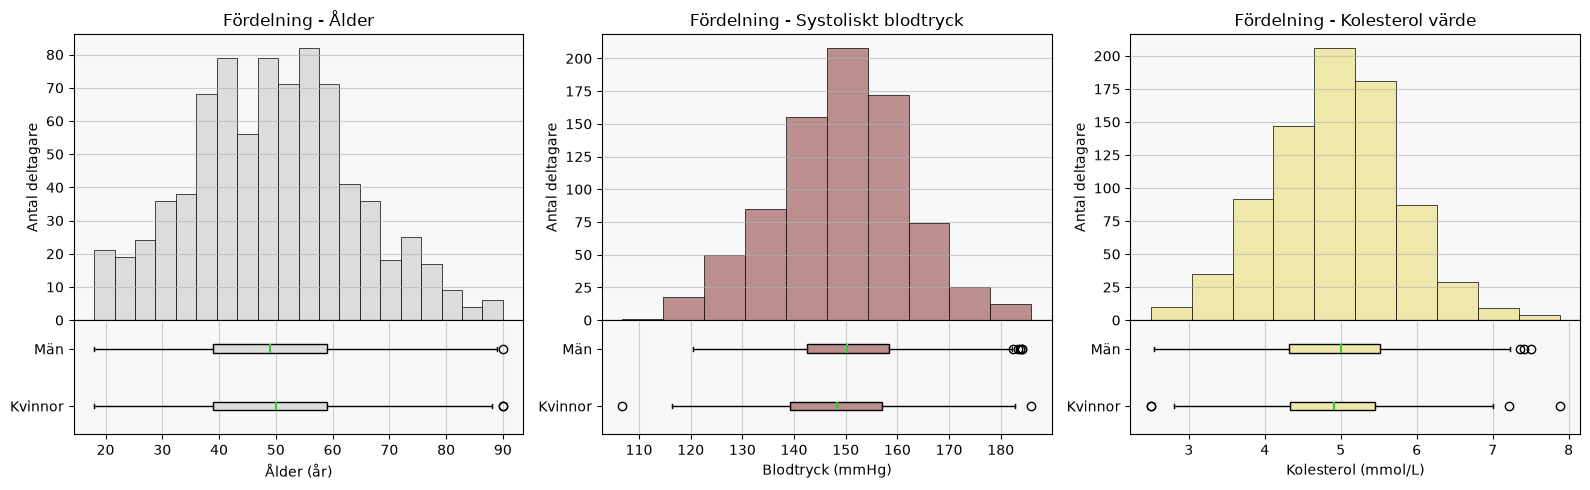

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 5), gridspec_kw={"height_ratios":[5,2], 'hspace': 0})

# age
axes[0,0].hist(data.age, bins=20, color='gainsboro', edgecolor='black', linewidth=0.5)
axes[0,0].set_facecolor("#F8F8F8")
axes[0,0].set_title("Fördelning - Ålder")
axes[0,0].set_xlabel("Ålder (år)")
axes[0,0].set_ylabel("Antal deltagare")
axes[0,0].grid(True, axis="y", alpha=0.6)

axes[1,0].boxplot([data.loc[data.sex == "F", "age"], 
                data.loc[data.sex == "M", "age"]], 
                tick_labels=["Kvinnor", "Män"], 
                patch_artist=True,
                # showmeans=True, meanline=True, 
                boxprops=dict(facecolor='gainsboro', edgecolor='black'),
                medianprops = dict(color="limegreen", linewidth=1.5),
                orientation='horizontal')
axes[1,0].set_facecolor("#F8F8F8")
axes[1,0].set_xlabel("Ålder (år)")
axes[1,0].grid(True, axis="x", alpha=0.6)


# systolic_bp
axes[0,1].hist(data.systolic_bp, bins=10, color='rosybrown', edgecolor='black', linewidth=0.5)
axes[0,1].set_facecolor("#F8F8F8")
axes[0,1].set_title("Fördelning - Systoliskt blodtryck")
axes[0,1].set_xlabel("Blodtryck (mmHg)")
axes[0,1].set_ylabel("Antal deltagare")
axes[0,1].grid(True, axis="y", alpha=0.6)

axes[1,1].boxplot([data.loc[data.sex == "F", "systolic_bp"], 
                data.loc[data.sex == "M", "systolic_bp"]], 
                tick_labels=["Kvinnor", "Män"], 
                patch_artist=True,
                # showmeans=True, meanline=True,
                boxprops=dict(facecolor='rosybrown', edgecolor='black'),
                medianprops = dict(color="limegreen", linewidth=1.5),
                orientation='horizontal')
axes[1,1].set_facecolor("#F8F8F8")
axes[1,1].set_xlabel("Blodtryck (mmHg)")
axes[1,1].grid(True, axis="x", alpha=0.6)


# cholesterol
axes[0,2].hist(data.cholesterol, bins=10, color='palegoldenrod', edgecolor='black', linewidth=0.5)
axes[0,2].set_facecolor("#F8F8F8")
axes[0,2].set_title("Fördelning - Kolesterol värde")
axes[0,2].set_xlabel("Kolesterol (mmol/L)")
axes[0,2].set_ylabel("Antal deltagare")
axes[0,2].grid(True, axis="y", alpha=0.6)

axes[1,2].boxplot([data.loc[data.sex == "F", "cholesterol"], 
                data.loc[data.sex == "M", "cholesterol"]], 
                tick_labels=["Kvinnor", "Män"], 
                patch_artist=True,
                # showmeans=True, meanline=True,
                boxprops=dict(facecolor='palegoldenrod', edgecolor='black'),
                medianprops = dict(color="limegreen", linewidth=1.5),
                orientation='horizontal')
axes[1,2].set_facecolor("#F8F8F8")
axes[1,2].set_xlabel("Kolesterol (mmol/L)")
axes[1,2].grid(True, axis="x", alpha=0.6)

plt.tight_layout()

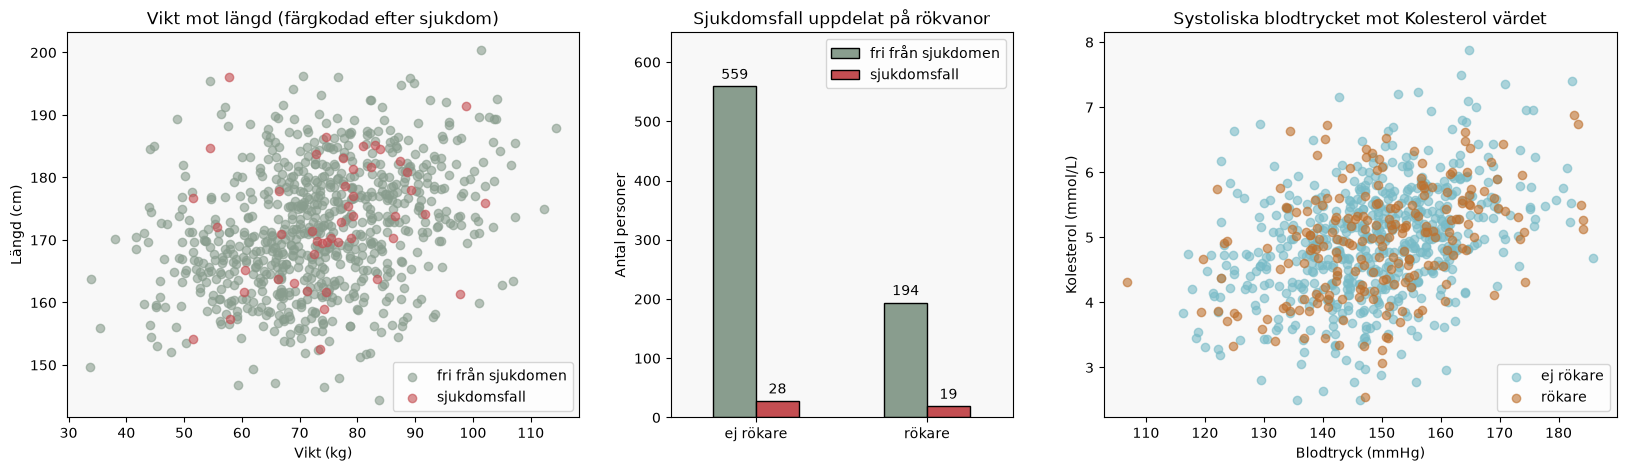

In [10]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 5), gridspec_kw={"width_ratios":[3,2,3]})

disease_n = data[data['disease'] == 0]
disease_y = data[data['disease'] == 1]

ax1.scatter(disease_n['weight'], disease_n['height'], color='#899D8E', label='fri från sjukdomen', alpha=0.6)
ax1.scatter(disease_y['weight'], disease_y['height'], color='#C44E52', label='sjukdomsfall', alpha=0.6)
ax1.set_facecolor("#F8F8F8")
ax1.set_title('Vikt mot längd (färgkodad efter sjukdom)')
ax1.set_xlabel('Vikt (kg)')
ax1.set_ylabel('Längd (cm)')
ax1.legend()


smoker_n = data[data["smoker"] == 0]
smoker_y = data[data["smoker"] == 1]

ax3.scatter(smoker_n["systolic_bp"], smoker_n["cholesterol"], color="#78BBC7", label='ej rökare', alpha=0.6)
ax3.scatter(smoker_y["systolic_bp"], smoker_y["cholesterol"], color="#BE712E", label='rökare', alpha=0.6)
ax3.set_facecolor("#F8F8F8")
ax3.set_title('Systoliska blodtrycket mot Kolesterol värdet')
ax3.set_xlabel("Blodtryck (mmHg)")
ax3.set_ylabel("Kolesterol (mmol/L)")
ax3.legend(loc="lower right")


gr_smoker_disease = data.groupby(['smoker', 'disease']).size().unstack()
gr_smoker_disease.plot(kind='bar', ax=ax2, color=["#899D8E", "#C44E52"], edgecolor='black')

for container in ax2.containers:
    ax2.bar_label(container, padding=3)

ax2.set_facecolor("#F8F8F8")
ax2.set_ylim(top=650)
ax2.set_title('Sjukdomsfall uppdelat på rökvanor')
ax2.set_xlabel('')
ax2.set_ylabel('Antal personer')
ax2.set_xticklabels(['ej rökare', 'rökare'], rotation=0)
ax2.legend(['fri från sjukdomen', 'sjukdomsfall'])

#### _<span style="color:orange">Observationer:</span>_

- **Ålder:** Ungefär symmetrisk/klockformad fördelning kring 50 år; liknande spridning hos både män och kvinnor.

- **Systoliskt blodtryck:** Koncentrerat kring 145–155 mmHg med några enstaka extremvärden (outliers) i lådagrammen.

- **Kolesterol:** Koncentrerat kring 5 mmol/L med liknande medianer och spridning mellan män och kvinnor.

- **Vikt mot längd (efter sjukdom):** Spridningsdiagrammet visar ett positivt samband mellan vikt och längd, där sjukdomsfall (röda punkter) förekommer över hela spridningen utan tydlig klustring i ett visst område.

- **Sjukdomsfall uppdelat på rökvanor:** Bland rökare är andelen som har sjukdomen större (~4,8%) än bland icke-rökare (~8,9%).

- **Systoliskt blodtryck mot kolesterol (efter rökvanor):** Svagt positivt samband mellan högre systoliskt blodtryck och högre kolesterolvärde för både rökare och icke-rökare.


    ***Funderingar:***
    - *Är alla värdena för vikt och längd är korrekta?*
    - *Inledningsvis gjorde jag antagandet att kolesterol avsåg LDL, men då rökning inte indikerar något avsevärt förhöjt kolesterol jämfört med icke rökare, antar jag nu att kolesterol värdet representerar Total kolesterolet.*
___

## Simulering kopplad till caset
- Beräkna andelen personer i datasetet som har sjukdomen.
- Använd numpy för att simulera 1000 slumpade personer med samma sannolikhet för sjukdom.
- Jämför den simulerade andelen med den verkliga andelen i datasetet.

In [11]:
actual_disease_rate = data["disease"].mean()

np.random.seed(42)
simulated_outcome = np.random.binomial(n=1, p=actual_disease_rate, size=1000)
simulated_disease_rate = simulated_outcome.mean()

print(f"Andel med sjukdomen (dataset):         {actual_disease_rate:.3%}")
print(f"Sannolikhet för sjukdom (simulering):  {simulated_disease_rate:.3%}")
print(f"Skillnad:                              {abs(actual_disease_rate - simulated_disease_rate)*100:.3}")

Andel med sjukdomen (dataset):         5.875%
Sannolikhet för sjukdom (simulering):  5.600%
Skillnad:                              0.275


## Konfidensintervall
- Beräkna ett konfidensintervall för medelvärdet av systolic_bp (t.ex. med normalapproximation eller bootstrap, som vi gått igenom på kursen).

_Beräkna konfidensintervallet med __två olika metoder__ (t.ex. normalapproximation och bootstrap) och jämför resultaten._

#### _Metod: Normalapproximation_

#### _Metod: Bootstrap_

#### _<span style="color:orange">Jämförelse av metoder:</span>_

___

## Hypotesprövning
- Testa hypotesen: ”Rökare har högre medel-blodtryck än icke-rökare.”
- Använd en av metoderna vi gått igenom (t.ex. bootstrap eller enkel t-test-funktion).
- Förklara kort resultatet i en markdown-ruta.

_Gör en simulering för att undersöka __hur säkert ditt hypotes­test är__ (t.ex. hur ofta testet hittar en skillnad när den finns → power)._

#### _<span style="color:orange">Resultat:</span>_

___